# Estrés inverso: el escenario más plausible que quiebra al banco

**Pregunta:** ¿Cuánto debe alejarse de su base el crecimiento real del PIB y el desempleo, sostenidos por tres años, para que
el CET1 de Banco Andino caiga al mínimo legal de la pila chilena, y cuán plausible es ese escenario?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 04 y 05 de este tema (los satélites y el plan de capital)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- plantear formalmente una prueba de estrés inverso, como el escenario de mínima distancia de Mahalanobis entre los que
  alcanzan un umbral de pérdida, y decir qué es su plausibilidad;
- calcular el punto de quiebre del banco, la holgura del CET1 sobre la pila legal chilena, como una pérdida en millones de
  pesos;
- construir la pérdida neta del banco como función de dos factores macro a partir de los satélites del motor y ver su forma;
- resolver el problema en forma cerrada sobre la pérdida linealizada y numéricamente sobre la pérdida verdadera desde cuatro
  puntos de partida, y ver por qué las dos respuestas difieren;
- comprobar la solución con el motor, ver la comprobación ponerse roja ante una falla plantada, y poner la respuesta en escala
  frente al escenario de la Reserva Federal y a la crisis financiera global.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lectores; la carpeta del flujo de generación va en la ruta porque nunca se instala
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.stress import capital, reverse, satellites
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c18 import satellites as c18_satellites


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee la variante de estrés inverso de **C18** (Banco Andino) y las piezas del escenario base con que se construye su pérdida.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/reverse-stress.json` (el punto de falla, el espacio de factores, la solución versionada y sus cuatro puntos de partida), `baseline.json` (la trayectoria base, el capital en el punto de partida, el PPNR y las pérdidas esperadas base, la exposición de cada clase de préstamo, las tasas de retroproyección), `models-banco-andino.json` (los coeficientes de los satélites) y `fed-2026-severely-adverse.json` (las filas de severidad que comparan el escenario con la crisis financiera global).
- **Los umbrales de Banco Andino son convenciones.** El punto de falla, el CET1 en la pila de mínimo legal, es la formulación del caso y **no es texto regulatorio**; la parte de CET1 del Pilar 2 en esa pila es un supuesto declarado (0,0625 por ciento de los APR).

In [2]:
# El documento de estrés inverso, las piezas base con que se construye su pérdida y los modelos de los satélites
baseline = read_json("C18/baseline.json")["outputs"]
reverse_doc = read_json("C18/reverse-stress.json")
solution_doc = reverse_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
fed = read_json("C18/fed-2026-severely-adverse.json")["outputs"]
failure = solution_doc["failure_point"]
start = baseline["capital_start"]
print(solution_doc["kind"], solution_doc["loss_model"]["kind"], failure["label"], failure["horizon_years"])

reverse nonlinear contraste-formulation-not-regulatory 3


## Método

### Paso 1: la pregunta y su enunciado formal

Una prueba de estrés parte de un escenario y pregunta qué pasa. Una **prueba de estrés inverso** parte de un resultado y pregunta qué escenarios lo causan: la guía europea EBA/GL/2018/04 la define como la que empieza con un resultado predefinido y explora los escenarios que podrían llevar a él (dossier 01, J.4). El enunciado formal es de Contraste, no texto regulatorio. Para una pérdida $L(x)$ como función de la **desviación $x$ de los factores macro respecto de su base**, con covarianza de factores $\Sigma$, el escenario más plausible que alcanza un umbral de pérdida $\ell$ es el de **mayor densidad** entre los que lo alcanzan, que para factores gaussianos (y elípticos) es el de **distancia de Mahalanobis mínima**:

$$x^{*} = \arg\min_x\; x^{\top}\Sigma^{-1}x \quad\text{sujeto a}\quad L(x) \ge \ell, \qquad d^{*} = \sqrt{x^{*\top}\Sigma^{-1}x^{*}}.$$

La atribución de este resultado elíptico a un artículo específico es NO VERIFICADA en el dossier (05, H.5); Glasserman, Kang y Kang (2015) estiman en cambio los escenarios más probables dadas pérdidas grandes por verosimilitud empírica, que el motor no implementa. Para una **pérdida lineal** $L(x) = g^{\top}x$ el problema tiene forma cerrada,

$$x^{*} = \frac{\Sigma g\,\ell}{g^{\top}\Sigma g}, \qquad d^{*} = \frac{\ell}{\sqrt{g^{\top}\Sigma g}},$$

y en otro caso se resuelve numéricamente. La **plausibilidad** de una solución es $P(\chi^2_k \ge d^{*2})$ con $k$ el número de factores: con qué frecuencia ocurre, bajo el modelo de factores, un escenario al menos así de lejos de la base.

La celda siguiente recalcula la pila con `chilean_cet1_stack` del motor y el umbral de pérdida del caso, la holgura del CET1 del
punto de partida sobre esa pila en millones de pesos, y dibuja las dos razones y la holgura entre ellas.

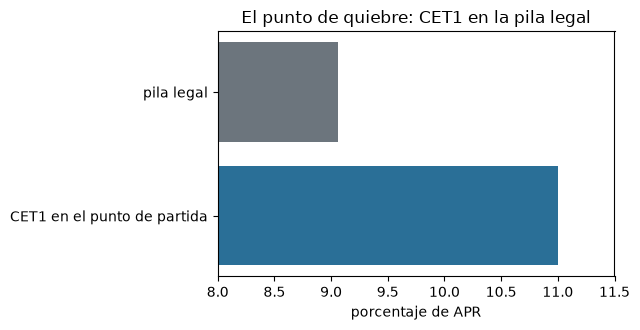

pila legal, porcentaje de APR 9.0625
razón CET1 en el punto de partida y APR 0.11 7492853.0
umbral de pérdida, millones de CLP 145174.0


In [3]:
# La pila legal de CET1 con el motor, y el umbral de pérdida: la holgura del CET1 sobre la pila
parts = failure["stack"]
stack = capital.chilean_cet1_stack(parts["c_ccyb"], parts["c_dsib"], parts["p2_cet1"]["value"])
threshold = (start["cet1_ratio"] - stack) * start["rwa_clp_m"]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(["CET1 en el punto de partida", "pila legal"], [start["cet1_ratio"] * 100, stack * 100],
        color=["#2a6f97", "#6c757d"])
ax.set_xlim(8, 11.5)
ax.set_xlabel("porcentaje de APR")
ax.set_title("El punto de quiebre: CET1 en la pila legal")
fig.tight_layout()
plt.show()
print("pila legal, porcentaje de APR", round(stack * 100, 4))
print("razón CET1 en el punto de partida y APR", start["cet1_ratio"], round(start["rwa_clp_m"], 1))
print("umbral de pérdida, millones de CLP", round(threshold, 1))

La razón CET1 del punto de partida, 11,0 por ciento, queda 1,9375 puntos sobre la pila legal de 9,0625 por ciento, que es 4,5
por ciento, 2,5 de conservación, los colchones contracíclico y sistémico y la parte CET1 del Pilar 2, y sobre APR de 7.492.853
millones de pesos esa holgura es una pérdida de 145.174,0 millones. Una prueba de estrés inverso pregunta qué escenario
produce una pérdida neta de ese tamaño en tres años, y la pregunta formal es la planteada arriba. El eje de la figura se
corta para empezar en 8 por ciento y poder ver la holgura, y el punto de quiebre es una formulación de Contraste, no texto
regulatorio.

### Paso 2: los factores

Los dos factores son el crecimiento del PIB real y la tasa de desempleo, los regresores de los satélites, y su comportamiento conjunto es la covarianza muestral de 1985 a 2019, la ventana de ajuste de los satélites. Un escenario aquí es una **desviación persistente** de ambos factores respecto de la trayectoria base de la Reserva Federal, la misma desviación en cada uno de los doce trimestres. El motor valida la covarianza antes de usarla (simétrica y definida positiva) y la rechaza en otro caso.

La celda siguiente lee la covarianza versionada de los dos factores, dibuja sus elipses de distancia de Mahalanobis 1, 2 y 3,
y muestra a `reverse_stress_linear` rechazando una covarianza que no es definida positiva.

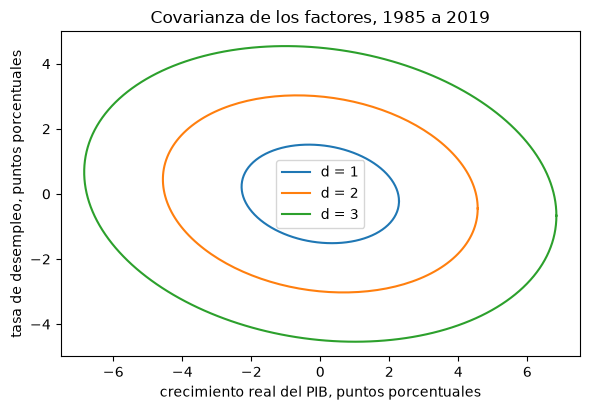

desviaciones estándar [2.2809 1.5136] correlación -0.1474
una covarianza que no es definida positiva es rechazada


In [4]:
# La covarianza de los factores, sus elipses de Mahalanobis y el rechazo de una covarianza que no es definida
# positiva
space = solution_doc["factor_space"]
cov = np.array(space["covariance"])
sd = np.array([f["sd"] for f in space["factors"]])
angle = np.linspace(0, 2 * np.pi, 200)
root = np.linalg.cholesky(cov)
fig, ax = plt.subplots(figsize=(6, 4.2))
for radius in (1, 2, 3):
    ellipse = root @ np.vstack([np.cos(angle), np.sin(angle)]) * radius
    ax.plot(ellipse[0], ellipse[1], label=f"d = {radius}")
ax.set_xlabel("crecimiento real del PIB, puntos porcentuales")
ax.set_ylabel("tasa de desempleo, puntos porcentuales")
ax.set_title("Covarianza de los factores, 1985 a 2019")
ax.legend()
fig.tight_layout()
plt.show()
print("desviaciones estándar", np.round(sd, 4), "correlación", round(float(cov[0, 1] / (sd[0] * sd[1])), 4))
try:
    reverse.reverse_stress_linear(np.array([1.0, 1.0]), np.array([[1.0, 2.0], [2.0, 1.0]]), 1.0)
except ValueError:
    print("una covarianza que no es definida positiva es rechazada")

Las elipses son los conjuntos de escenarios igualmente probables bajo el modelo de factores: un punto sobre el anillo de
distancia 2 es menos probable que uno a distancia 1 e igual de probable que cualquier otro punto de ese anillo. Están
ligeramente inclinadas porque el crecimiento y el desempleo se mueven en sentidos opuestos, con una correlación de menos
0,147, y son más anchas a lo largo del crecimiento, cuya desviación estándar es 2,28 puntos, que del desempleo, con 1,51. El
motor rechaza una covarianza que no sea simétrica y definida positiva, como la matriz impresa al final, porque una distancia
de Mahalanobis no tiene sentido sin ella.

### Paso 3: la pérdida del banco como función de los factores

La pérdida del estrés inverso es la **pérdida a tres años del banco neta del PPNR acumulado base**: el CET1 del punto de partida más el PPNR acumulado menos las pérdidas acumuladas llega exactamente a la pila legal cuando esta pérdida neta iguala la holgura del paso 1. Se construye con piezas que el notebook ya usó. Para una desviación $x = (x_{\text{PIB}}, x_{\text{desempleo}})$:

1. desplazar en $x$ la trayectoria base del regresor de cada trimestre;
2. proyectar los cinco satélites (notebook 04) desde las últimas tasas realizadas;
3. mezclar los tipos de préstamo en las tres clases con los pesos del caso y tomar, para cada año, la exposición de cada clase por el promedio de sus cuatro tasas trimestrales;
4. sumar las pérdidas esperadas de mercado y operacional a tres años (3 veces la cifra anual) y restar el PPNR acumulado del escenario base.

Es el mismo cableado de la propia `loss_fn` del flujo de generación (`data-pipeline/pipeline/cases/c18/bake.py`), con todo estadístico proveniente de `project_scenario` del motor.

La celda siguiente reúne la trayectoria base, las últimas tasas realizadas, las exposiciones por clase y las dos piezas
constantes de la pérdida neta, y reconstruye los cinco satélites del notebook 04 a partir de los coeficientes versionados. La
mezcla por clase y la pérdida de crédito anual son las funciones `class_rates` y `credit_losses` del propio flujo de generación.

In [5]:
# La trayectoria base, las últimas tasas, las exposiciones por clase y las dos piezas constantes de la pérdida
# neta
NAMES = ("real_gdp_growth", "unemployment_rate")
base_paths = {p["maps_to_regressor"]: p for p in baseline["scenario"]["paths"]}
base_path = np.column_stack([[row["value"] for row in base_paths[name]["transposed"]] for name in NAMES])
jump_off = np.array([[base_paths[name]["transposition"]["target"]["value"] for name in NAMES]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in baseline["backcast"]["per_loan_type"]}
exposure = {k["banco_andino_class"]: k["exposure_clp_m"] for k in baseline["satellites"]["banco_andino_classes"]}
marginals = baseline["aggregation"]["marginals"]
other_expected = sum(m["el_clp_m"] for m in marginals if m["risk"] in ("market", "operational"))
baseline_ppnr = sum(row["ppnr_clp_m"] for row in baseline["headline_cet1"]["ppnr"]["rows"])


def satellite_fit(model):
    names = list(dict.fromkeys(r["name"] for r in model["regressors"]))
    coefficients = model["coefficients"]
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"],
        n_obs=model["n_obs"], ar_order=model["ar_order"], regressor_names=tuple(names),
        lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in coefficients),
        estimates=tuple(c["estimate"] for c in coefficients),
        std_errors=tuple(c["std_error"] for c in coefficients), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


fits = {m["fed_loan_type"]: satellite_fit(m) for m in models["satellites"]}
last_link = {t: satellites.link(f.link, np.array([last_rate[t]])) for t, f in fits.items()}

La celda siguiente define la pérdida neta de una desviación $x$ de los dos factores, la función que recibe el solucionador del
motor: desplaza la trayectoria base en $x$, proyecta los cinco satélites con `project_scenario`, y deja que las funciones del
flujo de generación los mezclen en clases y sumen tres años de pérdida de crédito. Dibuja la pérdida neta a lo largo de cada
eje de factor contra el umbral.

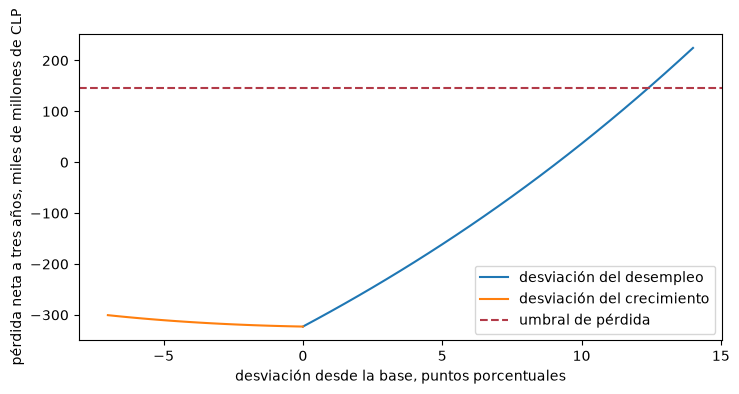

otras pérdidas esperadas por año 1187.54
PPNR base a tres años 441263.1
pérdida neta en la base -322940.3
x = [-1.0, 0.0]: pérdida neta   -321,627.4
x = [0.0, 3.0]: pérdida neta   -229,840.7
x = [-2.0, 6.0]: pérdida neta   -124,811.9
x = [-2.58, 12.42]: pérdida neta    145,240.8


In [6]:
# La pérdida neta como función de las dos desviaciones de los factores y su forma a lo largo de cada eje
def net_loss(x):
    path = base_path + np.asarray(x, dtype=float)
    projections = {t: satellites.project_scenario(f, last_link[t], jump_off, path) for t, f in fits.items()}
    credit = sum(c18_satellites.credit_losses(c18_satellites.class_rates(projections), exposure))
    return float(credit) + 3.0 * other_expected - baseline_ppnr


steps = np.linspace(0, 14, 29)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(steps, [net_loss([0.0, u]) / 1e3 for u in steps], label="desviación del desempleo")
ax.plot(-steps / 2, [net_loss([-g, 0.0]) / 1e3 for g in steps / 2], label="desviación del crecimiento")
ax.axhline(threshold / 1e3, color="#b23a48", linestyle="--", label="umbral de pérdida")
ax.set_xlabel("desviación desde la base, puntos porcentuales")
ax.set_ylabel("pérdida neta a tres años, miles de millones de CLP")
ax.legend()
fig.tight_layout()
plt.show()
print("otras pérdidas esperadas por año", round(other_expected, 2))
print("PPNR base a tres años", round(baseline_ppnr, 1))
print("pérdida neta en la base", round(net_loss([0.0, 0.0]), 1))
for x in ([-1.0, 0.0], [0.0, 3.0], [-2.0, 6.0], [-2.58, 12.42]):
    print(f"x = {x}: pérdida neta {net_loss(x):12,.1f}")

En la base la pérdida neta es menos 322.940 millones, porque el PPNR base a tres años, 441.263 millones, supera a las pérdidas,
así que el banco está a 468.114 millones de pérdida neta del punto de quiebre y «ningún estrés» no es la pregunta aquí. La
curva del desempleo se dobla hacia arriba y cruza el umbral cerca de 12,4 puntos, mientras la del crecimiento, en un rango de
7 puntos, es casi plana: un punto de crecimiento mueve la pérdida en 1.055 millones y un punto de desempleo en 29.244. Los
satélites hacen del desempleo el factor dominante, y por eso la solución será una gran desviación del desempleo y una pequeña
del crecimiento.

### Paso 4: la forma cerrada sobre la pérdida linealizada

La pérdida no es lineal, por el enlace probit, pero en la base tiene un **gradiente** $g = \nabla L(0)$ en millones de CLP por punto porcentual de cada factor, que dan las diferencias finitas centrales. La aproximación lineal es $L(x) \approx L(0) + g^{\top}x$, así que la pérdida alcanza el umbral $\ell$ cuando $g^{\top}x = \ell - L(0)$, y `reverse_stress_linear(g, cov, ell - L(0))` devuelve el escenario en forma cerrada. El signo del gradiente dice la economía: negativo en el crecimiento del PIB (menos crecimiento, más pérdida) y positivo en el desempleo.

La celda siguiente calcula el gradiente por diferencias centrales, llama a `reverse_stress_linear` con la pérdida por cubrir, y
dibuja la pérdida neta verdadera y su linealización a lo largo de la dirección de la solución en forma cerrada, contra el
umbral.

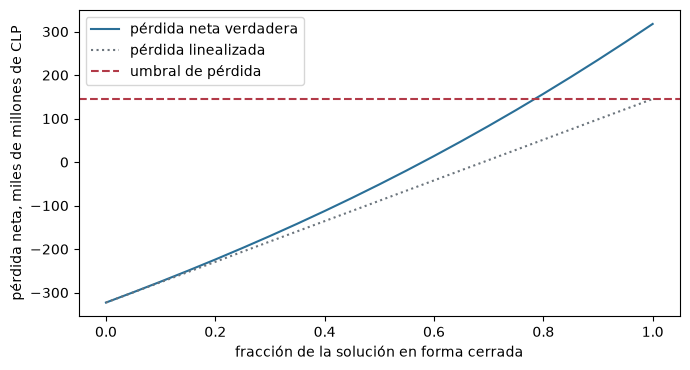

gradiente, millones de CLP por punto (PIB, desempleo) [-1055. 29244.]
x* lineal, distancia [-4.776 15.835] 10.4767
pérdida verdadera en el x* lineal, millones de CLP 317698.6
pérdida verdadera sobre el umbral 2.2
plausibilidad del escenario lineal 1.46e-24


In [7]:
# Gradiente de la pérdida neta en la base, la solución en forma cerrada del problema lineal y su pérdida
# verdadera
h = 1e-4
gradient = np.array([(net_loss(np.eye(2)[k] * h) - net_loss(-np.eye(2)[k] * h)) / (2 * h) for k in range(2)])
loss_at_zero = net_loss([0.0, 0.0])
linear = reverse.reverse_stress_linear(gradient, cov, threshold - loss_at_zero)
scale = np.linspace(0, 1, 21)
true_curve = [net_loss(linear.x_star * s) / 1e3 for s in scale]
linear_curve = [(loss_at_zero + float(gradient @ linear.x_star) * s) / 1e3 for s in scale]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(scale, true_curve, color="#2a6f97", label="pérdida neta verdadera")
ax.plot(scale, linear_curve, color="#6c757d", linestyle=":", label="pérdida linealizada")
ax.axhline(threshold / 1e3, color="#b23a48", linestyle="--", label="umbral de pérdida")
ax.set_xlabel("fracción de la solución en forma cerrada")
ax.set_ylabel("pérdida neta, miles de millones de CLP")
ax.legend()
fig.tight_layout()
plt.show()
print("gradiente, millones de CLP por punto (PIB, desempleo)", np.round(gradient, 0))
print("x* lineal, distancia", np.round(linear.x_star, 3), round(linear.distance, 4))
true_loss = net_loss(linear.x_star)
print("pérdida verdadera en el x* lineal, millones de CLP", round(true_loss, 1))
print("pérdida verdadera sobre el umbral", round(true_loss / threshold, 1))
print("plausibilidad del escenario lineal", f"{reverse.plausibility(linear.distance, 2):.2e}")

La linealización es una recta desde la base, y la pérdida verdadera es una curva convexa sobre ella, porque el vínculo probit
convierte incrementos macro iguales en tasas de pérdida crecientes. En el escenario de la forma cerrada, menos 4,78 puntos de
crecimiento y más 15,84 de desempleo a una distancia de 10,48, la pérdida lineal apenas alcanza el umbral, pero la verdadera
ahí es de 317.699 millones de pesos, 2,2 veces más. La forma cerrada se pasa, y el escenario verdadero que solo alcanza el
umbral queda más cerca de la base. Esa es la razón del cálculo no lineal del paso siguiente.

### Paso 5: el problema no lineal, desde varios puntos de partida

El problema verdadero es no lineal, así que `reverse_stress(loss_fn, cov, threshold, starts)` del motor minimiza $x^{\top}\Sigma^{-1}x$ sujeto a $L(x) \ge \ell$ con SLSQP desde cada punto de partida (gradientes por diferencias centrales y reinicios en caliente). **Una búsqueda local no prueba nada desde un solo punto**, así que se exigen al menos tres puntos y se devuelve la mejor solución convergida con el resultado de cada punto. Un punto converge cuando SLSQP tiene éxito y la pérdida está dentro de una tolerancia relativa del umbral. Los cuatro puntos del caso son puntos deterministas en el cuadrante adverso (el crecimiento cae, el desempleo sube), en múltiplos de las desviaciones estándar de los factores: $(-1, 5)$, $(-0,5; 7)$, $(-2, 8)$ y $(0, 9)$.

La celda siguiente ejecuta `reverse_stress` desde los cuatro puntos de partida del caso, imprime cada uno con la fila
versionada al lado, y dibuja las elipses de Mahalanobis con el contorno donde la pérdida neta verdadera iguala al umbral, la
base, la solución en forma cerrada y la no lineal.

In [8]:
# Resolver el problema no lineal desde los cuatro inicios del caso e imprimir cada uno junto al versionado
starts = [np.array([a * sd[0], b * sd[1]]) for a, b in ((-1.0, 5.0), (-0.5, 7.0), (-2.0, 8.0), (0.0, 9.0))]
best, each = reverse.reverse_stress(net_loss, cov, threshold, starts)
committed = solution_doc["solution"]
for k, (mine, theirs) in enumerate(zip(each, solution_doc["starts"]), start=1):
    print(f"inicio {k}: convergió {mine.converged!s:5s} distancia {mine.distance:.9f}")
    print(f"   versionada: {theirs['converged']!s:5s} {theirs['distance']:.9f}")
print("x* =", np.round(best.x_star, 4), "z* =", np.round(best.z_star, 4), "distancia", round(best.distance, 6))
print("pérdida en x*, umbral", round(best.loss_at_x, 3), round(threshold, 3))
print("plausibilidad P(chi2_2 >= d^2)", f"{reverse.plausibility(best.distance, 2):.2e}")
print("versionada", f"{committed['plausibility']['tail_probability']:.2e}")

inicio 1: convergió True  distancia 8.205018940
   versionada: True  8.205018940
inicio 2: convergió False distancia 8.205018940
   versionada: False 8.205018940
inicio 3: convergió True  distancia 8.205018940
   versionada: True  8.205018940
inicio 4: convergió True  distancia 8.205018940
   versionada: True  8.205018940
x* = [-2.5805 12.4186] z* = [-1.1313  8.2046] distancia 8.205019
pérdida en x*, umbral 145174.027 145174.027
plausibilidad P(chi2_2 >= d^2) 2.41e-15
versionada 2.41e-15


La celda siguiente evalúa la pérdida neta en una grilla del plano de los factores, lo que toma unos segundos, y dibuja el
contorno donde iguala al umbral sobre las elipses de Mahalanobis.

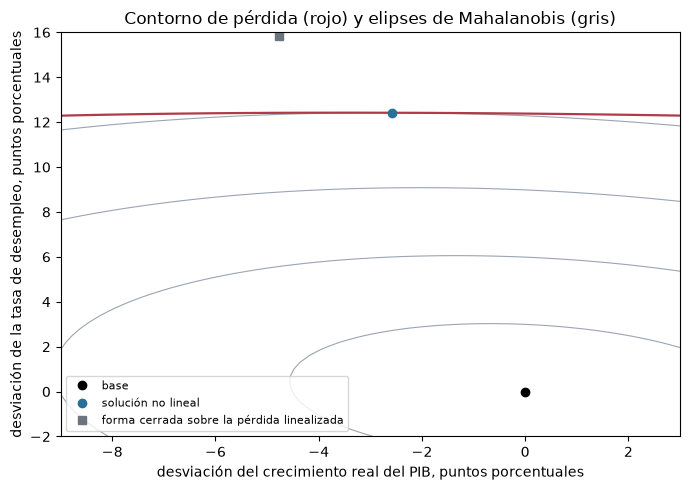

In [9]:
# Las elipses de Mahalanobis, el contorno donde la pérdida neta iguala al umbral y las dos soluciones
gx, gy = np.linspace(-9, 3, 61), np.linspace(-2, 16, 61)
grid_loss = np.array([[net_loss([a, b]) for a in gx] for b in gy])
p = np.linalg.inv(cov)
xx, yy = np.meshgrid(gx, gy)
distance_grid = np.sqrt(p[0, 0] * xx ** 2 + 2 * p[0, 1] * xx * yy + p[1, 1] * yy ** 2)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(gx, gy, distance_grid, levels=[2, 4, 6, round(best.distance, 3)], colors="#9aa5b1", linewidths=0.8)
ax.contour(gx, gy, grid_loss, levels=[threshold], colors="#b23a48", linewidths=1.6)
ax.plot([0], [0], "ko", label="base")
ax.plot(*best.x_star, "o", color="#2a6f97", label="solución no lineal")
ax.plot(*linear.x_star, "s", color="#6c757d", label="forma cerrada sobre la pérdida linealizada")
ax.set_xlabel("desviación del crecimiento real del PIB, puntos porcentuales")
ax.set_ylabel("desviación de la tasa de desempleo, puntos porcentuales")
ax.set_title("Contorno de pérdida (rojo) y elipses de Mahalanobis (gris)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

El contorno rojo es donde la pérdida neta verdadera iguala al umbral, y la solución es su punto más cercano a la base en
distancia de Mahalanobis, donde el contorno es tangente a la última elipse gris, de distancia 8,2. Queda en menos 2,58 puntos
de crecimiento y más 12,42 de desempleo, en desviaciones estándar menos 1,13 y más 8,20, y el cuadrado de la forma cerrada
más allá está más lejos, como explicó la figura anterior. Tres de los cuatro puntos de partida convergieron y el cuarto se
detuvo en la misma distancia con doce dígitos, que es lo que una búsqueda local debe mostrar antes de creer su respuesta: las
distancias impresas coinciden con las versionadas, y la plausibilidad, 2,41e-15, es cuán rara es tal escenario bajo el modelo
de factores.

### Paso 6: comprobar la solución

Un optimizador numérico puede detenerse en un punto que no es solución, así que el motor trae una verificación, `reverse_solution_check(loss_at_x, threshold, distance, start_distances)`: **roja** cuando la pérdida en la solución no alcanza el umbral por más de una tolerancia, o cuando algún punto de partida encontró un punto más cercano que la solución; **verde** en otro caso; `not_evaluated` con menos de tres puntos. Su métrica es el punto más cercano sobre la distancia de la solución, menos 1 (cero o positiva cuando ningún punto es más cercano).

La celda siguiente ejecuta `reverse_solution_check` del motor sobre la solución y las distancias de los puntos de partida
convergidos, sobre una falla plantada, y sobre solo dos puntos de partida.

In [10]:
# Ejecutar la comprobación de solución del motor sobre la solución real, sobre una falla plantada y sobre solo
# dos inicios
converged = [s.distance for s in each if s.converged]
LIGHT = {"green": "verde", "red": "rojo", "not_evaluated": "no evaluada"}
planted = converged[:-1] + [0.9 * best.distance]
cases = (("la solución", converged), ("un inicio al 90 por ciento de la distancia", planted),
         ("solo dos inicios", converged[:2]))
for label, distances in cases:
    check = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, distances)
    print(f"{label:48s} {LIGHT[check.light.value]:14s} {len(distances)}")

la solución                                      verde          3
un inicio al 90 por ciento de la distancia       rojo           3
solo dos inicios                                 no evaluada    2


### Paso 7: ¿cuán severo es el escenario que rompe al banco?

La solución es una desviación de ambos factores, **sostenida por doce trimestres**, respecto de la base. Dos puntos de referencia le dan escala. El escenario severamente adverso de la Reserva Federal llega a un máximo 5,5 puntos sobre su desempleo inicial, que la fila de severidad versionada del caso compara con los 5,1 puntos de la crisis financiera global (2008 T1 a 2009 T4).

La celda siguiente lee las filas de severidad, expresa la solución en desviaciones estándar de cada factor, y dibuja la
desviación del desempleo de la solución junto al máximo de la Reserva Federal y al de la crisis financiera global.

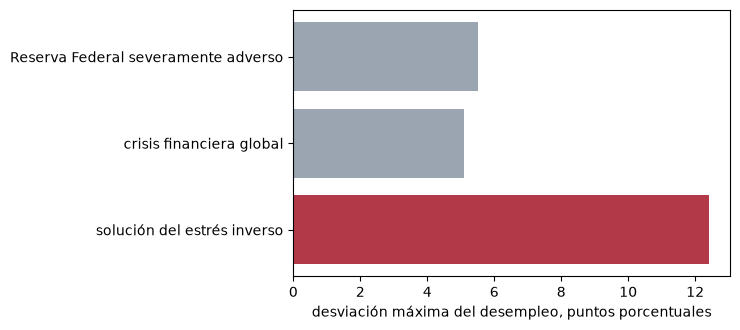

solución, crecimiento del PIB y desempleo, puntos -2.58 12.42
máximos, Reserva Federal y crisis 5.5 5.1000000000000005
en desviaciones estándar [-1.13  8.2 ]
múltiplos de los máximos de la Reserva Federal y la crisis
[2.3 2.4]
probabilidad de cola 2.41e-15
desviaciones estándar normales equivalentes 7.83


In [11]:
# Comparar la solución con el escenario de la Reserva Federal y la crisis financiera global en el factor
# desempleo
severity = {row["maps_to_regressor"]: row for row in fed["severity"]["rows"]}
unemployment = severity["unemployment_rate"]
x_gdp, x_unemployment = best.x_star
labels = ["Reserva Federal severamente adverso", "crisis financiera global",
          "solución del estrés inverso"]
values = [unemployment["path_peak_deviation"], unemployment["history_peak_deviation"], x_unemployment]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(labels[::-1], values[::-1], color=["#b23a48", "#9aa5b1", "#9aa5b1"])
ax.set_xlabel("desviación máxima del desempleo, puntos porcentuales")
fig.tight_layout()
plt.show()
print("solución, crecimiento del PIB y desempleo, puntos", round(x_gdp, 2), round(x_unemployment, 2))
print("máximos, Reserva Federal y crisis", values[0], values[1])
print("en desviaciones estándar", np.round(best.z_star, 2))
print("múltiplos de los máximos de la Reserva Federal y la crisis")
print(np.round(x_unemployment / np.array(values[:2]), 1))
tail = reverse.plausibility(best.distance, 2)
print("probabilidad de cola", f"{tail:.2e}")
print("desviaciones estándar normales equivalentes", round(float(stats.norm.isf(tail)), 2))

La desviación del desempleo que quiebra al banco, 12,42 puntos sostenidos por doce trimestres, es 2,3 veces el máximo
severamente adverso de la Reserva Federal de 5,5 y 2,4 veces los 5,1 puntos de la crisis financiera global. En desviaciones
estándar del modelo de factores es 8,2, equivalente a una variable normal sola en 7,83 desviaciones estándar. El gráfico de
barras pone la respuesta en una escala que el lector ya tiene: el banco de este caso sintético no quiebra en ningún escenario
del registro histórico. Eso dice más del modelo de pérdida que de la economía, pues la pérdida es un piso y el PPNR lleva dos
razones supuestas.

## Resultados

Las dos figuras anteriores llevan el resultado: el plano de los factores con el contorno de pérdida y la solución, y el gráfico
de barras que pone su desviación del desempleo junto a los dos puntos de referencia. Los números que responden la pregunta son
los impresos bajo ellas.

**Respuesta:** el escenario más plausible que lleva a Banco Andino a la pila legal es una desviación persistente de menos 2,58
puntos del crecimiento real del PIB y más 12,42 puntos de desempleo, sostenida por doce trimestres, a una distancia de
Mahalanobis de 8,205019, con un umbral de pérdida de 145.174,0 millones de pesos y una plausibilidad de 2,4e-15, 7,83
desviaciones estándar de una variable normal sola. La desviación del desempleo es 2,3 veces el máximo severamente adverso de la
Reserva Federal de 5,5 puntos y 2,4 veces los 5,1 de la crisis financiera global. La forma cerrada sobre la pérdida
linealizada habría dicho menos 4,78 y más 15,84 a una distancia de 10,48, con 2,2 veces demasiada pérdida en la solución,
porque el vínculo probit es convexo; y la comprobación de la solución es verde con tres puntos de partida convergidos y roja
cuando se planta un inicio al 90 por ciento de la distancia.

Lo que este notebook no muestra: la pérdida es un piso (los riesgos de mercado y operacional llevan solo su pérdida esperada) y
su PPNR es una fila etiquetada sobre razones supuestas, así que la distancia es una propiedad de este modelo y sus entradas;
los satélites sobre los que corre fallan su propia retroproyección (notebook 07), lo que es una razón para leer la distancia
como una afirmación sobre los satélites; y el estimador de verosimilitud empírica de Glasserman, Kang y Kang no está en el
motor.

## Resumen

- Una prueba de estrés inverso parte de la falla y pide el escenario más plausible que la alcanza; el enunciado formal del caso es el escenario de distancia de Mahalanobis mínima sobre la superficie de pérdida, formulación de Contraste y no texto regulatorio.
- El punto de falla es el CET1 en la pila de mínimo legal chilena al final de los tres años; el umbral es la holgura del CET1 sobre ella, y la pérdida es la pérdida a tres años neta del PPNR base.
- Para una pérdida lineal la solución es de forma cerrada; la pérdida del caso es no lineal por el enlace probit, así que el motor la resuelve numéricamente desde varios puntos y una verificación rechaza una solución que no alcanza el umbral o que tiene un punto más cercano.
- El escenario que rompe al banco está muy más allá de todo estrés del registro: necesita un desplazamiento persistente del desempleo de más del doble del máximo severamente adverso de la Reserva Federal y una plausibilidad cercana a $10^{-15}$ bajo el modelo de factores, lo que dice más de la resiliencia del banco en este caso sintético, y de lo que omiten sus insumos, que de la economía.

**Qué probar a continuación.** Cambia la parte de CET1 del Pilar 2 en la pila del paso 1 y mira moverse el umbral y la distancia; luego sigue con el notebook 07, que valida los componentes de agregación y estrés con las baterías de pruebas del motor.

## Referencias

- Glasserman, P., Kang, C. y Kang, W. (2015), Stress scenario selection by empirical likelihood, Quantitative Finance 15(1). https://doi.org/10.1080/14697688.2014.926019
- Dossiers 01 (J.4, la formulación del estrés inverso y EBA/GL/2018/04) y 05 (H.5, pruebas de estrés inverso) de la investigación persistida de Contraste, resumidos en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (las funciones de estrés inverso) y `docs/design/features/c18/requirements.md` (CT-1815 y CT-1822).